# Notebook 2: Late Delivery Analysis and Prediction
**Business question:** Which orders are at risk of arriving late, and what drives it?
**Data:** order items joined with orders, customers, products, and categories from the `supply_chain` SQL Server database.
**Target:** `Late`, which is 1 if the order was delivered late and 0 if not.

## 1. Load the data
Loaded order items joined to orders, customers, products, and categories directly from SQL Server. The result has 180,519 rows, matching the database, with one row per order item.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

engine = create_engine(
    "mssql+pyodbc://localhost\\SQLEXPRESS/supply_chain"
    "?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes&TrustServerCertificate=yes"
)

query = """
SELECT oi.Order_Item_Id, oi.Order_Id, oi.Quantity, oi.Sales, oi.Discount_Rate,
       o.Order_Date, o.Shipping_Mode, o.Delivery_Status, o.Late_Delivery_Risk,
       o.Days_Shipping_Scheduled, o.Market, o.Order_Region, o.Payment_Type,
       c.Customer_Segment, cat.Category_Name
FROM order_items oi
JOIN orders o      ON oi.Order_Id = o.Order_Id
JOIN customers c   ON o.Customer_Id = c.Customer_Id
JOIN products p    ON oi.Product_Card_Id = p.Product_Card_Id
JOIN categories cat ON p.Category_Id = cat.Category_Id
"""
df = pd.read_sql(query, engine)
df.shape

(180519, 15)

## 2. Define the target
Removed the 7,754 rows with status "Shipping canceled." The audit showed these are canceled or suspected-fraud orders, and they are all labeled "not late" even though they never completed a normal delivery, so keeping them would distort the late rate.

That leaves **172,765 order items**, of which **57.3% were late**. This is the baseline to beat: a model that always guesses "late" is right 57.3% of the time.

In [14]:
df = df[df["Delivery_Status"] != "Shipping canceled"].copy()
df["Late"] = df["Late_Delivery_Risk"].astype(int)
print(df.shape, "| overall late rate:", round(df["Late"].mean(), 3))

(172765, 16) | overall late rate: 0.573


## 3. Late rate by group
Shipping mode is the only variable with a large effect:

| Shipping mode | Late rate |
|---|---|
| First Class | 100% |
| Second Class | about 80% |
| Same Day | about 48% |
| Standard Class | about 40% |

Market, customer segment, and payment type are almost flat, with late rates between 56.6% and 57.7% in every group. Where the customer is and how they pay do not explain lateness.

**Operations finding:** First Class, the premium option, is late on every order. Slower modes perform better than faster ones.

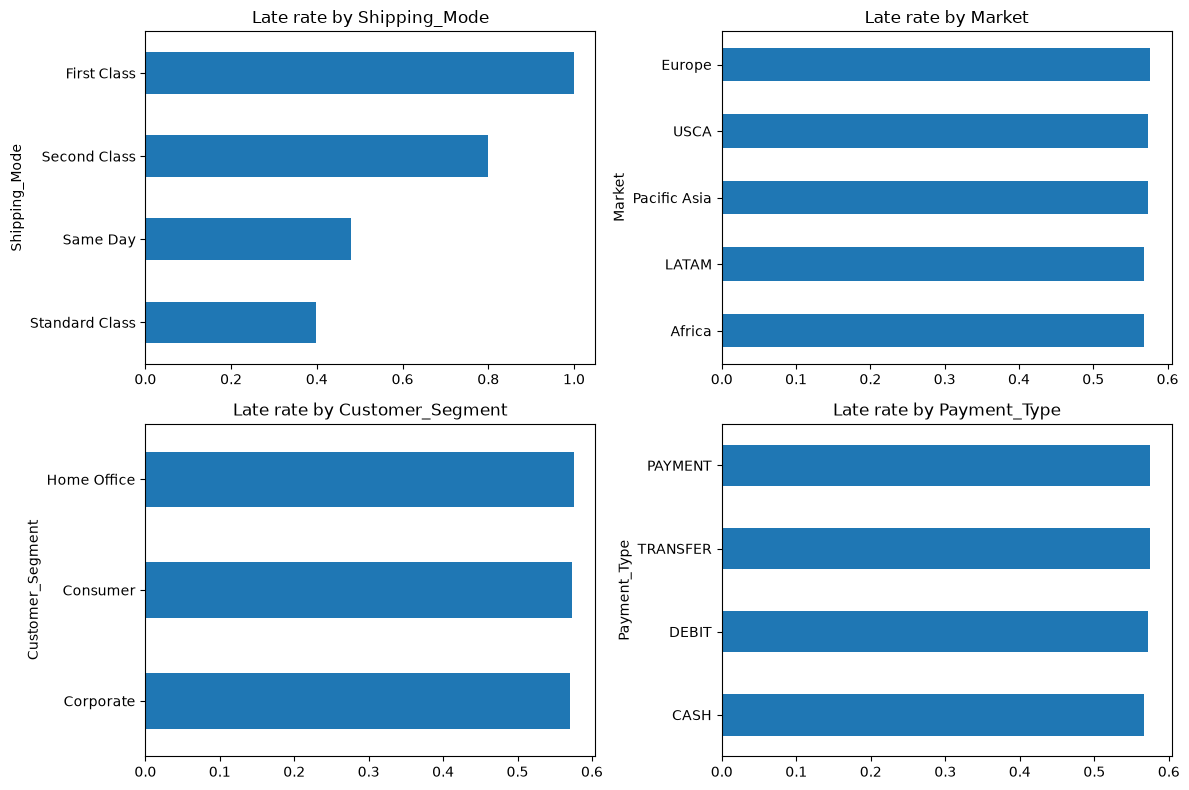

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["Shipping_Mode", "Market", "Customer_Segment", "Payment_Type"]):
    df.groupby(col)["Late"].mean().sort_values().plot(kind="barh", ax=ax, title=f"Late rate by {col}")
plt.tight_layout()
plt.show()

## 4. Shipping mode and scheduled days are the same variable
Each shipping mode maps to exactly one scheduled delivery time: Same Day = 0 days, First Class = 1, Second Class = 2, Standard Class = 4. The two columns carry identical information, so the model will use only one of them.

This also means the First Class result is a planning problem: it is scheduled for 1 day and never arrives within it.

In [16]:
pd.crosstab(df["Shipping_Mode"], df["Days_Shipping_Scheduled"])

Days_Shipping_Scheduled,0,1,2,4
Shipping_Mode,,,,
First Class,0,26513,0,0
Same Day,9293,0,0,0
Second Class,0,0,33806,0
Standard Class,0,0,0,103153


## 5. Statistical test
A chi-square test checks whether lateness is related to a category or just looks different by chance.

- **Shipping mode:** p-value is effectively 0, so the relationship is real.
- **Market:** p = 0.10, not significant at the usual 0.05 cutoff.
- **Customer segment:** p = 0.35, not significant.
- **Payment type:** p = 0.16, not significant.

Only shipping mode has a statistically significant link to late delivery. This matches the charts.

In [17]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Shipping_Mode"], df["Late"])
chi2, p, dof, expected = chi2_contingency(table)
print("p-value:", p)

p-value: 0.0


## Summary of exploration
- 172,765 deliveries analyzed after removing canceled orders; 57.3% were late.
- Shipping mode is the only meaningful driver. First Class is late 100% of the time.
- Market, customer segment, and payment type show no significant relationship with lateness.
- Next: build a model and test whether anything beyond shipping mode improves predictions.

## Part 2: Predictive Model
**Question:** Can we predict which orders will be late, and do any factors beyond shipping mode help?

### Features
**Used:** shipping mode, market, region, customer segment, payment type, category, quantity, sales, discount rate, and order month and weekday. These are all known when the order is placed.

**Excluded on purpose:**
- `Delivery_Status` and real shipping days, because they reveal the outcome (found in the audit).
- `Days_Shipping_Scheduled`, because it is the same variable as shipping mode.

In [25]:
df["Order_Month"] = pd.to_datetime(df["Order_Date"]).dt.month
df["Order_Weekday"] = pd.to_datetime(df["Order_Date"]).dt.dayofweek

cat_cols = ["Shipping_Mode", "Market", "Order_Region", "Customer_Segment", "Payment_Type", "Category_Name"]
num_cols = ["Quantity", "Sales", "Discount_Rate", "Order_Month", "Order_Weekday"]

X = df[cat_cols + num_cols]
y = df["Late"]

### Train/test split
Split 80/20 **by order**, not by row. One order can have several items that all share the same lateness label, so a plain random split would put pieces of the same order in both sets and inflate the score. Confirmed that no order appears in both sets. A plain split gave the random forest a ROC-AUC of about 0.76, versus 0.74 with this correct split.

In [26]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df["Order_Id"]))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(X_train.shape, X_test.shape)
print("Orders in both sets:", len(set(df.iloc[train_idx]["Order_Id"]) & set(df.iloc[test_idx]["Order_Id"])))

(138493, 11) (34272, 11)
Orders in both sets: 0


### Baseline
Always predicting "late" is right 57.5% of the time. Any model has to beat this to be useful.

In [27]:
baseline = max(y_test.mean(), 1 - y_test.mean())
print("Baseline accuracy (always guess late):", round(baseline, 3))

Baseline accuracy (always guess late): 0.575


### Model results

| Model | Accuracy | ROC-AUC |
|---|---|---|
| Always guess "late" (baseline) | 0.575 | 0.50 |
| Logistic regression | 0.692 | 0.739 |
| Random forest | 0.691 | 0.740 |
| Shipping mode only | 0.692 | 0.738 |

All three models beat the baseline by about 12 points. **But the full models perform the same as a model using shipping mode alone.** Market, region, segment, category, discount, and timing add nothing.

Reading the shipping-mode model's report:
- **Precision on late orders is about 0.88:** when it predicts late, it is right 88% of the time.
- **Recall on late orders is about 0.54:** it only catches just over half of the orders that are actually late.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report

def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"--- {name} ---")
    print("Accuracy:", round(accuracy_score(y_test, pred), 3), "| ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, digits=3))
    return model

# Logistic regression (numeric columns scaled so it converges)
prep_scaled = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)])
logit = Pipeline([("prep", prep_scaled), ("model", LogisticRegression(max_iter=1000))])
logit = evaluate("Logistic regression", logit, X_train, X_test)

# Random forest
prep_plain = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)], remainder="passthrough")
rf = Pipeline([("prep", prep_plain),
               ("model", RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1))])
rf = evaluate("Random forest", rf, X_train, X_test)

# Shipping mode only
mode_only = Pipeline([("prep", ColumnTransformer([("cat", OneHotEncoder(), ["Shipping_Mode"])])),
                      ("model", LogisticRegression())])
mode_only = evaluate("Shipping mode only", mode_only, X_train[["Shipping_Mode"]], X_test[["Shipping_Mode"]])

--- Logistic regression ---
Accuracy: 0.692 | ROC-AUC: 0.739
[[13113  1437]
 [ 9114 10608]]
              precision    recall  f1-score   support

           0      0.590     0.901     0.713     14550
           1      0.881     0.538     0.668     19722

    accuracy                          0.692     34272
   macro avg      0.735     0.720     0.690     34272
weighted avg      0.757     0.692     0.687     34272

--- Random forest ---
Accuracy: 0.692 | ROC-AUC: 0.74
[[12438  2112]
 [ 8458 11264]]
              precision    recall  f1-score   support

           0      0.595     0.855     0.702     14550
           1      0.842     0.571     0.681     19722

    accuracy                          0.692     34272
   macro avg      0.719     0.713     0.691     34272
weighted avg      0.737     0.692     0.690     34272

--- Shipping mode only ---
Accuracy: 0.692 | ROC-AUC: 0.738
[[13132  1418]
 [ 9142 10580]]
              precision    recall  f1-score   support

           0      0.590

### Feature importance
The four shipping mode columns hold about 91% of the random forest's total importance. Every other feature is at 0.012 or lower. This agrees with the chi-square tests in Part 1, where only shipping mode was significant.

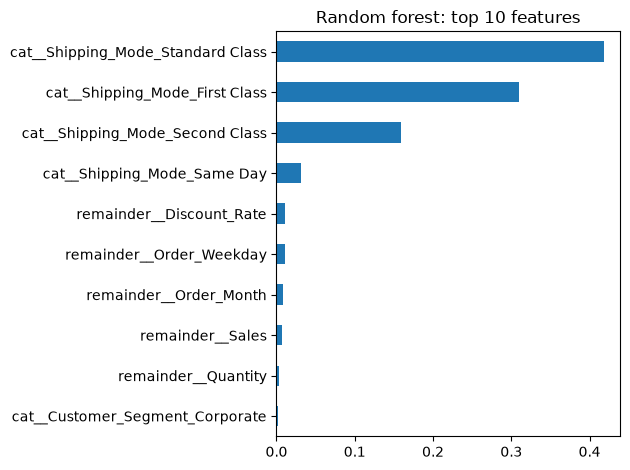

In [29]:
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh", title="Random forest: top 10 features")
plt.tight_layout()
plt.show()

## Conclusions
1. **Lateness is predictable only through shipping mode.** Beyond that, nothing in this dataset identifies *which* Standard Class or Same Day orders will be late, so those stay close to a coin flip.
2. **A more complex model did not help.** The random forest and logistic regression match a one-variable model, which means the information is not in the data.
3. **First Class is late on every order,** even though it is the premium, 1-day option. Standard Class has the best on-time rate (about 60%).

**Recommendations**
- Review the First Class promise: either fix the process or change the scheduled delivery time to a realistic one.
- To predict lateness better, collect more data, such as carrier, warehouse, weather, or order volume.

**Limitations**
- The data appears simulated, so real-world drivers of lateness may be missing.
- Canceled and suspected-fraud orders were excluded, and the data structure changes in October 2017 (see Notebook 1).